# Data Preparation - `triage.csv`

In [1]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict
from sklearn.preprocessing import MinMaxScaler

import seaborn as sns
from scipy.stats import pearsonr


In [2]:
# Loading Datasets
triage_df = pd.read_csv('../datasets/patients_traige.csv')
len_init_triage = len(triage_df)
triage_df_cp = triage_df.copy()

In [3]:
triage_df

,Unnamed: 0,subject_id,stay_id,temperature,heartrate,resprate,o2sat,sbp,dbp,pain,acuity,chiefcomplaint
0,0,10000032,32952584,97.8,87.0,14.0,97.0,71.0,43.0,7,2.0,Hypotension
1,1,10000032,33258284,98.4,70.0,16.0,97.0,106.0,63.0,0,3.0,"Abd pain, Abdominal distention"
2,2,10000032,35968195,99.4,105.0,18.0,96.0,106.0,57.0,10,3.0,"n/v/d, Abd pain"
3,3,10000032,38112554,98.9,88.0,18.0,97.0,116.0,88.0,10,3.0,Abdominal distention
4,4,10000032,39399961,98.7,77.0,16.0,98.0,96.0,50.0,13,2.0,"Abdominal distention, Abd pain, LETHAGIC"
...,...,...,...,...,...,...,...,...,...,...,...,...
105954,425078,19999733,30940569,98.0,60.0,18.0,100.0,120.0,71.0,0,3.0,? SEIZURE TODAY
105955,425080,19999784,34149746,98.8,92.0,18.0,100.0,122.0,77.0,0,3.0,Wound eval
105956,425081,19999784,35692999,98.6,80.0,18.0,100.0,161.0,100.0,0,3.0,L Leg weakness
105957,425082,19999784,37972930,98.0,91.0,16.0,99.0,148.0,90.0,5,2.0,Abnormal MRI


## **Data Cleaning**

In [4]:
triage_df = triage_df.drop(columns=["Unnamed: 0"])

In [5]:
triage_df.head()

,subject_id,stay_id,temperature,heartrate,resprate,o2sat,sbp,dbp,pain,acuity,chiefcomplaint
0,10000032,32952584,97.8,87.0,14.0,97.0,71.0,43.0,7,2.0,Hypotension
1,10000032,33258284,98.4,70.0,16.0,97.0,106.0,63.0,0,3.0,"Abd pain, Abdominal distention"
2,10000032,35968195,99.4,105.0,18.0,96.0,106.0,57.0,10,3.0,"n/v/d, Abd pain"
3,10000032,38112554,98.9,88.0,18.0,97.0,116.0,88.0,10,3.0,Abdominal distention
4,10000032,39399961,98.7,77.0,16.0,98.0,96.0,50.0,13,2.0,"Abdominal distention, Abd pain, LETHAGIC"


In [6]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
tr_tmp_column = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'acuity']
print(triage_df[tr_tmp_column].describe())

        temperature     heartrate      resprate         o2sat           sbp  \
count  97486.000000  99593.000000  98573.000000  98540.000000  99336.000000   
mean      97.996130     85.698687     17.858273     98.052107    136.413010   
std        2.677759     19.159192      6.323605      9.306535     25.054448   
min        0.300000      9.000000      1.000000      0.000000     10.000000   
25%       97.500000     72.000000     16.000000     97.000000    120.000000   
50%       98.000000     84.000000     18.000000     98.000000    134.000000   
75%       98.600000     97.000000     18.000000    100.000000    151.000000   
max      146.880000    230.000000   1796.500000   1007.000000    960.000000   

                dbp         acuity  
count  99132.000000  103456.000000  
mean      78.209396       2.381834  
std       86.719158       0.693399  
min        0.000000       1.000000  
25%       66.000000       2.000000  
50%       76.000000       2.000000  
75%       87.000000       3.0

In [7]:
triage_df_cp.shape

(105959, 12)

- `temperature` : $\text{Se } X \notin [82, 105.8] \Rightarrow X \text{ è un outlier}$
- `heartrate`: $\text{Se } X \notin [40, 220] \Rightarrow X \text{ è un outlier}$
- `resprate` : $\text{Se } X \notin [8, 35] \Rightarrow X \text{ è un outlier}$
- `o2sat` : $\text{Se } X \notin [70, 100] \Rightarrow X \text{ è un outlier}$
- `sbp` : $\text{Se } X \notin [70, 180] \Rightarrow X \text{ è un outlier}$
- `dbp` : $\text{Se } X \notin [40, 120] \Rightarrow X \text{ è un outlier}$

In [8]:
triage_df = triage_df[(triage_df['temperature'] >= 82) & (triage_df['temperature'] <= 105.8)]
triage_df = triage_df[(triage_df['heartrate'] >= 40) & (triage_df['heartrate'] <= 220)]
triage_df = triage_df[(triage_df['resprate'] >= 8) & (triage_df['resprate'] <= 35)]
triage_df = triage_df[(triage_df['o2sat'] >= 70) & (triage_df['o2sat'] <= 100)]
triage_df = triage_df[(triage_df['sbp'] >= 70) & (triage_df['sbp'] <= 180)]
triage_df = triage_df[(triage_df['dbp'] >= 40) & (triage_df['dbp'] <= 120)]
print(len(triage_df)) # tot in dataset 105959. Rimanenti 89138
print("Ramaining values percentage: ", len(triage_df)/len(triage_df_cp)*100)

89138
Ramaining values percentage:  84.12499174208892


In [9]:
# Conta e calcola la percentuale di valori mancanti
missing_values = triage_df.isnull().sum()
missing_percentage = (missing_values / len(triage_df)) * 100
print(pd.DataFrame({'Missing val': missing_values, '    |     Missing %': missing_percentage}))


                Missing val      |     Missing %
subject_id                0             0.000000
stay_id                   0             0.000000
temperature               0             0.000000
heartrate                 0             0.000000
resprate                  0             0.000000
o2sat                     0             0.000000
sbp                       0             0.000000
dbp                       0             0.000000
pain                    894             1.002939
acuity                   29             0.032534
chiefcomplaint            1             0.001122


**Osservazione**: 
- essendo `pain, chiefcomplaint` categoriale non influenzano anormalmente i possibili comportamenti studiati. Per cui quei dati mancanti verranno identificati come `unknown`
- mentre `acuity`, vengono rimossi, per evitare di avere un paziente con una patologia molto dolorosa e mettergli il valore medio, che non tornerebbe. 

In [10]:
# triage_df.dropna(subset=['acuity'], inplace=True)
triage_df['pain'] = triage_df['pain'].fillna('unknown')
triage_df['chiefcomplaint'] = triage_df['chiefcomplaint'].fillna('unknown')

In [11]:
triage_df.columns

Index(['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate',
       'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint'],
      dtype='object')

In [12]:
subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'acuity']

In [13]:
print(triage_df[subset_column_num].describe())

        temperature     heartrate      resprate         o2sat           sbp  \
count  89138.000000  89138.000000  89138.000000  89138.000000  89138.000000   
mean      98.091879     85.730839     17.730609     98.024093    133.801084   
std        1.006671     18.619139      2.367344      2.201393     20.555896   
min       82.600000     40.000000      8.000000     70.000000     70.000000   
25%       97.500000     72.000000     16.000000     97.000000    119.000000   
50%       98.000000     84.000000     18.000000     98.000000    133.000000   
75%       98.600000     97.000000     18.000000    100.000000    149.000000   
max      105.800000    217.000000     35.000000    100.000000    180.000000   

                dbp        acuity  
count  89138.000000  89109.000000  
mean      76.090848      2.455038  
std       14.342305      0.646095  
min       40.000000      1.000000  
25%       66.000000      2.000000  
50%       76.000000      2.000000  
75%       86.000000      3.000000  


In [14]:
triage_df.shape

(89138, 11)

## **Analisi Outlier**

Numero di outliers in temperature: 1965
Numero di outliers in heartrate: 367
Numero di outliers in resprate: 3182
Numero di outliers in o2sat: 704
Numero di outliers in sbp: 0
Numero di outliers in dbp: 0


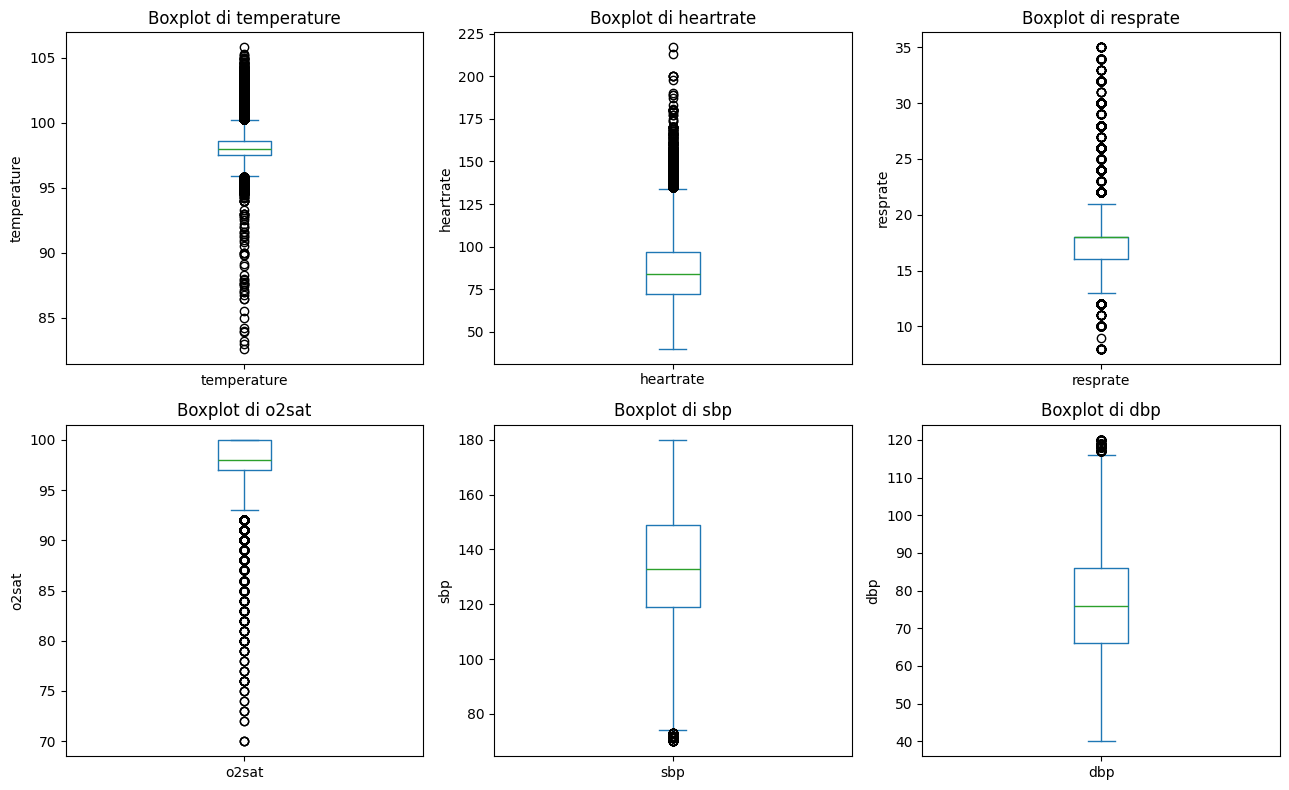

In [15]:
columns = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']

n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 4 * n_rows))
k = 2
for idx, col in enumerate(columns):
    Q1 = triage_df[col].quantile(0.25)
    Q3 = triage_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - k * IQR
    upper_bound = Q3 + k * IQR
    outliers = triage_df[(triage_df[col] < lower_bound) | (triage_df[col] > upper_bound)]
    print(f"Numero di outliers in {col}: {len(outliers)}")
    row = idx // n_cols
    col_idx = idx % n_cols
    ax = axes[row, col_idx]
    triage_df[col].plot(kind='box', ax=ax, title=f'Boxplot di {col}')
    ax.set_ylabel(col)

for i in range(len(columns), n_rows * n_cols):
    fig.delaxes(axes.flat[i])
plt.tight_layout()
plt.show()


### Save cleaning Data

In [16]:
# Salva il DataFrame ripulito in un nuovo file CSV
triage_df.to_csv('../datasets/triage_cleaned.csv', index=False)

### **Matrix correlation**

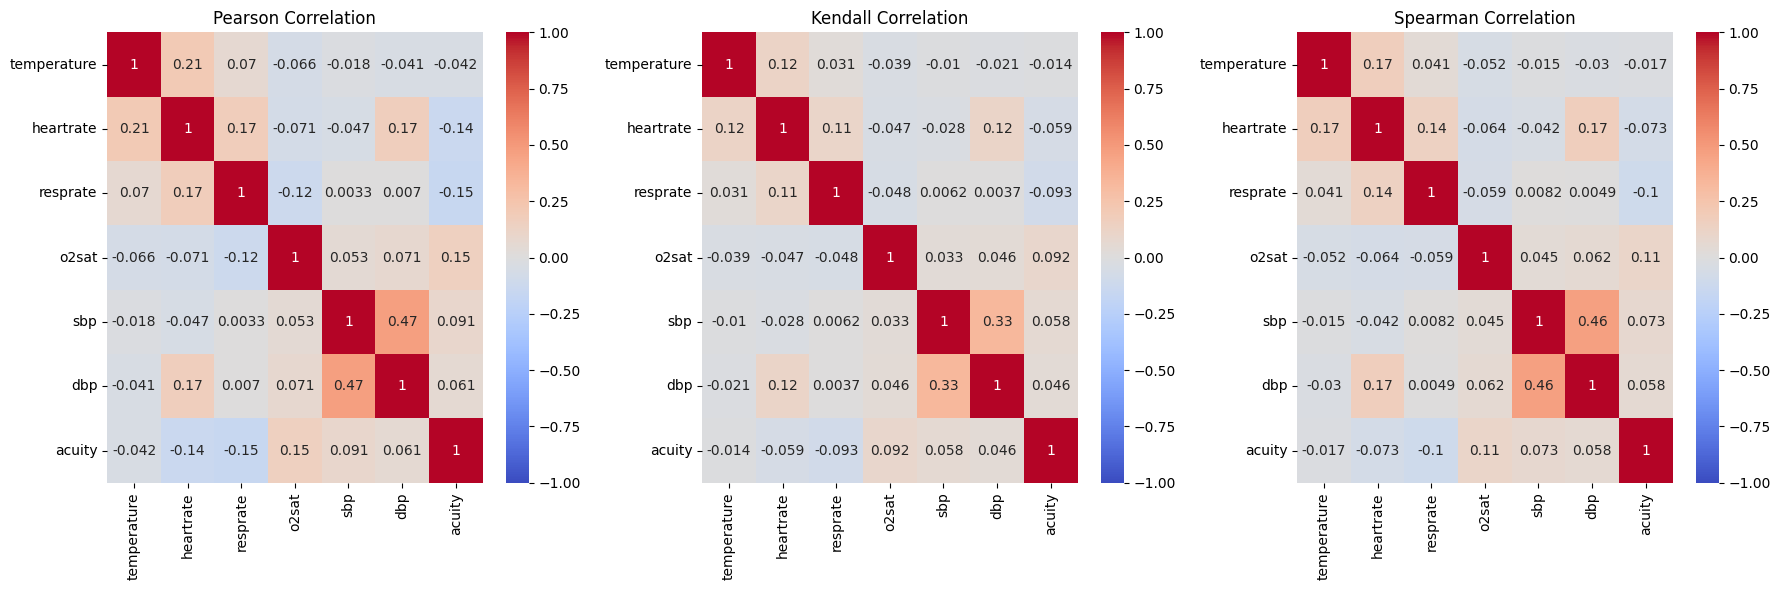

In [17]:
subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'acuity']
correlation_pearson = triage_df[subset_column_num].corr(method='pearson')
correlation_kendall = triage_df[subset_column_num].corr(method='kendall')
correlation_spearman = triage_df[subset_column_num].corr(method='spearman')

correlation_matrices = [correlation_pearson, correlation_kendall, correlation_spearman]
titles = ['Pearson Correlation', 'Kendall Correlation', 'Spearman Correlation']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for idx, (matrix, title) in enumerate(zip(correlation_matrices, titles)):
    sns.heatmap(matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[idx])
    axes[idx].set_title(title)
plt.tight_layout()
plt.show()

---
### **Cleaning Categorical Data**

In [18]:
triage_df = pd.read_csv('../datasets/triage_cleaned.csv')

In [19]:
triage_df['pain'].nunique()

317

In [20]:
triage_df['pain'].unique()

array(['7', '0', '10', '13', '3', '8', '4', '6', '5', '2', '1', 'unknown',
       'Non-verbal', '9', 'unable', 'ua', 'Critical', '>10', '5-6', 'UTA',
       'UA', 'yes', 'uta', 'ok', 'o', '7.5', 'leg pain', '3-4', 'unable ',
       '8.5', '9.5', '?', ' 0', 'sore', '15-20', '20', '0 ', '10 ', '2-3',
       '6-7', 'denies', 'u/a', 'asleep', '___', 'Bad', 'alot', 'sleeping',
       'unqble', 'UTA ', 'burning', '7-8', 'no', 'uta ', '6.5',
       'unable to score - abd pain', '1.5', 'not much', 'very painful',
       '"pain"', 'not bad', 's', '0-10', '4-5', '8-9', '1-2', '11',
       '"hurts everywhere"', 'bad', 'mild', '4 ', 'uable', 'Unable',
       'it hurts', 'yes - R arm', '0.5', '8 ', 'unable to rate',
       'moderate', '"yes"', 'Unresponsive', '5.8', '12', '7/8', '-',
       'unbale', '7.5-8', '10+', '101', 'dull', 'xc', '"alittle"',
       '"pains"', '0.', 'a lot', 'unable to score', '"alot"', '4.5',
       'pain', '"not bad" ', 'discomfort', '8/6', 'gi upset',
       'hurts alot',

In [21]:
# Converti tutto in minuscolo
tmp_df = triage_df.copy()
triage_df['pain'] = triage_df['pain'].str.lower()
print(f"Len DOPO: {triage_df['pain'].nunique()}")
print(f"Len PRIMA: {tmp_df['pain'].nunique()}")

Len DOPO: 302
Len PRIMA: 317


In [22]:
# Rimuovi spazi all'inizio e alla fine
triage_df['pain'] = triage_df['pain'].str.strip()
print(f"Len DOPO: {triage_df['pain'].nunique()}")


Len DOPO: 279


In [23]:
triage_df['pain'].unique()

array(['7', '0', '10', '13', '3', '8', '4', '6', '5', '2', '1', 'unknown',
       'non-verbal', '9', 'unable', 'ua', 'critical', '>10', '5-6', 'uta',
       'yes', 'ok', 'o', '7.5', 'leg pain', '3-4', '8.5', '9.5', '?',
       'sore', '15-20', '20', '2-3', '6-7', 'denies', 'u/a', 'asleep',
       '___', 'bad', 'alot', 'sleeping', 'unqble', 'burning', '7-8', 'no',
       '6.5', 'unable to score - abd pain', '1.5', 'not much',
       'very painful', '"pain"', 'not bad', 's', '0-10', '4-5', '8-9',
       '1-2', '11', '"hurts everywhere"', 'mild', 'uable', 'it hurts',
       'yes - r arm', '0.5', 'unable to rate', 'moderate', '"yes"',
       'unresponsive', '5.8', '12', '7/8', '-', 'unbale', '7.5-8', '10+',
       '101', 'dull', 'xc', '"alittle"', '"pains"', '0.', 'a lot',
       'unable to score', '"alot"', '4.5', 'pain', '"not bad"',
       'discomfort', '8/6', 'gi upset', 'hurts alot', '9-10', 'unablw',
       'ra', '"12"', 'some', 'heaviness', 'unaable', '5.5', 'uanble',
       '16', '

In [24]:
def contains_number(value):
    return any(char.isdigit() for char in str(value))

pain_with_numbers = triage_df[triage_df['pain'].apply(contains_number)]
pain_without_numbers = triage_df[~triage_df['pain'].apply(contains_number)]
print("Numero di righe con almeno un numero in 'pain':", len(pain_with_numbers))
print("Numero di righe senza numeri in 'pain':", len(pain_without_numbers))

print("Righe con almeno un numero in 'pain':")
print(pain_with_numbers['pain'].unique())

print("Righe senza numeri in 'pain':")
print(pain_without_numbers['pain'].unique())


Numero di righe con almeno un numero in 'pain': 85620
Numero di righe senza numeri in 'pain': 3518
Righe con almeno un numero in 'pain':
['7' '0' '10' '13' '3' '8' '4' '6' '5' '2' '1' '9' '>10' '5-6' '7.5' '3-4'
 '8.5' '9.5' '15-20' '20' '2-3' '6-7' '7-8' '6.5' '1.5' '0-10' '4-5' '8-9'
 '1-2' '11' '0.5' '5.8' '12' '7/8' '7.5-8' '10+' '101' '0.' '4.5' '8/6'
 '9-10' '"12"' '5.5' '16' '4.4' '68' '.5' '19' '15' '18' '4-6' '"11"' '6.'
 '8/' '97.5' '"10"' '6-9' 'o3' '`10' '1/2' '6-8' '3.' '.0' '90' '7.235'
 '-0' '0-' '4 knee and neck pain' '109' '00' '30' '2.' '46' '8.2' '3-5'
 '.3' '0..' '1-10' '0-1' '70' '7-9' '95' '96' '-1' '9.7' '73' '2-4' '0-5'
 '134' '<1' '67' '"30"' 'faces 4' '8.5-9' '0-8' '2-7' '09' '5-8' '01'
 '1/10' '"20"' '0-4' '30-40' '7-7.5' '3.5' '2-8' '22' '0-7' '06' '0,'
 '2/3']
Righe senza numeri in 'pain':
['unknown' 'non-verbal' 'unable' 'ua' 'critical' 'uta' 'yes' 'ok' 'o'
 'leg pain' '?' 'sore' 'denies' 'u/a' 'asleep' '___' 'bad' 'alot'
 'sleeping' 'unqble' 'burning' 'no

**Osservazione**: 
- Analisi prima numerica dei valori di `pain`:
    - num <0 saranno settati a 0
    - num >10 saranno settati a 10

In [25]:
def is_float(val):
    try:
        float(val)
        return True
    except ValueError:
        return False


def numero_trattino_numero(value):
    numeri = value.split('-')
    if len(numeri) == 2 and is_float(numeri[0]) and is_float(numeri[1]):
        num1, num2 = float(numeri[0]), float(numeri[1])
        media = (num1 + num2) / 2
        return str(int(round(media, 0)))
    else:
        return value


def numero_slash_numero(value):
    numeri = value.split('/')
    if len(numeri) == 2 and is_float(numeri[0]) and is_float(numeri[1]):
        return str(int(round(float(numeri[0]) / float(numeri[1]), 0)))
    else:
        return value


def extract_number(value):
    number = ""
    for char in value:
        if char.isdigit():  
            number += char
            if float(number) >= 10:
                return '10'
    return str(number) if is_float(number) else value


def delete_single_char(value):
    if len(value) == 1 and not is_float(value):
        return ''
    else:
        return value


def greater_than_10(value):
    if pd.isna(value):
        return value
    value = str(value)
    value = value.replace('"', '').replace('`', '').replace('..', '')
    if "-" in value:
        value = numero_trattino_numero(value)
    if '/' in value:
        value = numero_slash_numero(value)
    if is_float(value):
        value = str(int(round(float(value), 0)))
    else:
        value = extract_number(value)
    value = delete_single_char(value)
    if value.isdigit():
        if float(value) > 10:
            return '10'
        elif float(value) < 0:
            return '0'
        else:
            return str(int(round(float(value), 0)))

    return value


# int(round(6.7, 0))
triage_df['pain'] = triage_df['pain'].apply(greater_than_10)
print(triage_df['pain'].unique())
print("LEN Triage generale PAIN", triage_df['pain'].nunique())

['7' '0' '10' '3' '8' '4' '6' '5' '2' '1' 'unknown' 'non-verbal' '9'
 'unable' 'ua' 'critical' 'uta' 'yes' 'ok' '' 'leg pain' 'sore' 'denies'
 'u/a' 'asleep' '___' 'bad' 'alot' 'sleeping' 'unqble' 'burning' 'no'
 'unable to score - abd pain' 'not much' 'very painful' 'pain' 'not bad'
 'hurts everywhere' 'mild' 'uable' 'it hurts' 'yes - r arm'
 'unable to rate' 'moderate' 'unresponsive' 'unbale' 'dull' 'xc' 'alittle'
 'pains' 'a lot' 'unable to score' 'discomfort' 'gi upset' 'hurts alot'
 'unablw' 'ra' 'some' 'heaviness' 'unaable' 'uanble' 'unable to obtain'
 'ams' 'nonverbal' 'unble' 'squeezing' 'tightness' 'declined' '??'
 'little' 'sharp' 'pressure' 'toothach' 'nad' 'neb' 'moans' 'bone pain'
 'a little' 'moaning' 'unable to assess' 'sleep' 'in knees' 'badly'
 'chronic pain' 'everything hurts' 'uta.' 'too much' 'not so bad' 'fine'
 'medium' 'really hurts' 'unable - sleeping' 'hurts' 'refused' 'alright'
 'unable moaning' 'slight' 'moderate pain' 'pretty ad' 'very bad' 'unwell'
 'utta' 

In [26]:
pain_with_numbers = triage_df[triage_df['pain'].apply(contains_number)]
print(pain_with_numbers['pain'].unique())
print(f"LEN pain num : {pain_with_numbers['pain'].nunique()}")


['7' '0' '10' '3' '8' '4' '6' '5' '2' '1' '9' '-1']
LEN pain num : 12


- https://www.medicalnewstoday.com/articles/pain-scale#unidimensional-scales
- https://www.iasp-pain.org/resources/faces-pain-scale-revised/?ItemNumber=1519
- https://wongbakerfaces.org/


In [27]:
pain_mapping = {
    'unable': ['unable', 'unqble', 'unbel', 'unale', 'unaable', 'uanble', 'uanble to answer', 'unalbe', 'u/a', 'uta', 'unble', 'u.a', 'unabl', 'uable', 'utta', 'unanble', 'unablwe', 'unalb e'],
    'critical': ['critical', 'crtiical', 'crit', 'crrit', 'crtiical', 'critical ', 'critcal'],
    'mild': ['mild', 'mild pain', 'not much', 'not bad', 'not very painful', 'light pain', 'not terrible'],
    'moderate': ['moderate', 'moderate pain', 'moderate '],
    'severe': ['severe', 'extreme', 'excruciating', 'severe pain', 'high pain', 'unbearable', 'intense', 'too much', 'hurts real bad', 'red'],
    'very bad': ['very bad'],
    'no pain': ['none', 'no', 'denies', 'no pain', 'absent', '0', '0.0'],
    # 'hurt' : ['hurt', 'it hurts', 'hurts'],
    'unknown': ['unknown', 'dont know', 'unknow n'],
    'refuse': ['refuse', 'refusing', 'refused', 'refuses'],
    'little bit' : ['little bit']
}

pain_number = {
    '0': ['no pain'],
    '2':['mild'],
    '3': ['little bit'],
    '5': ['moderate'],
    '8': ['very bad'],
    '9': ['severe'],
    '10': ['critical', 'trauma', 'horrible']
}


def map_pain(value):
    if not is_float(value):
        for standard, variants in pain_mapping.items():
            if (standard in value) or (value in variants):
                return standard
            if '?' in value:
                return np.nan
        return value
    else:
        return value

def map_pain_to_number(value):
    if not is_float(value):
        for standard, variants in pain_number.items():
            if value in variants:
                return standard
        return value
    else:
        return value
    
    
triage_df['pain'] = triage_df['pain'].apply(map_pain)
triage_df['pain'] = triage_df['pain'].apply(map_pain_to_number)
print(triage_df['pain'].unique())
print("LEN Triage generale PAIN", triage_df['pain'].nunique())

['7' '0' '10' '3' '8' '4' '6' '5' '2' '1' 'unknown' 'non-verbal' '9'
 'unable' 'ua' 'yes' 'ok' '' 'leg pain' 'sore' 'asleep' '___' 'bad' 'alot'
 'sleeping' 'burning' 'very painful' 'pain' 'hurts everywhere' 'it hurts'
 'yes - r arm' 'unresponsive' 'unbale' 'dull' 'xc' 'alittle' 'pains'
 'a lot' 'discomfort' 'gi upset' 'hurts alot' 'unablw' 'ra' 'some'
 'heaviness' 'ams' 'nonverbal' 'squeezing' 'tightness' 'declined' nan
 'little' 'sharp' 'pressure' 'toothach' 'nad' 'neb' 'moans' 'bone pain'
 'a little' 'moaning' 'sleep' 'in knees' 'badly' 'chronic pain'
 'everything hurts' 'uta.' 'not so bad' 'fine' 'medium' 'really hurts'
 'hurts' 'refuse' 'alright' 'slight' 'pretty ad' 'unwell' 'pretty bad'
 'unkno' 'a lot of pain' 'varies' 'ut' 'not really' 'mucho'
 'hardly anything' 'not alot' 'a little more' 'no answer' 'tenderness'
 'arm hurts' 'heartburn' 'uncomfortable' '-1' 'unk' 'ache all over'
 'excrutiating' 'heavy' 'please help me' 'tolerable' 'manageable'
 'everywhere' 'vent/uta' 'uto' 'i

In [28]:
pain_without_numbers = triage_df[~triage_df['pain'].apply(contains_number)]

print("Righe senza numeri in 'pain':")
print(pain_without_numbers['pain'].unique())
print(f"LEN pain num : {pain_without_numbers['pain'].nunique()}")


Righe senza numeri in 'pain':
['unknown' 'non-verbal' 'unable' 'ua' 'yes' 'ok' '' 'leg pain' 'sore'
 'asleep' '___' 'bad' 'alot' 'sleeping' 'burning' 'very painful' 'pain'
 'hurts everywhere' 'it hurts' 'yes - r arm' 'unresponsive' 'unbale'
 'dull' 'xc' 'alittle' 'pains' 'a lot' 'discomfort' 'gi upset'
 'hurts alot' 'unablw' 'ra' 'some' 'heaviness' 'ams' 'nonverbal'
 'squeezing' 'tightness' 'declined' nan 'little' 'sharp' 'pressure'
 'toothach' 'nad' 'neb' 'moans' 'bone pain' 'a little' 'moaning' 'sleep'
 'in knees' 'badly' 'chronic pain' 'everything hurts' 'uta.' 'not so bad'
 'fine' 'medium' 'really hurts' 'hurts' 'refuse' 'alright' 'slight'
 'pretty ad' 'unwell' 'pretty bad' 'unkno' 'a lot of pain' 'varies' 'ut'
 'not really' 'mucho' 'hardly anything' 'not alot' 'a little more'
 'no answer' 'tenderness' 'arm hurts' 'heartburn' 'uncomfortable' 'unk'
 'ache all over' 'excrutiating' 'heavy' 'please help me' 'tolerable'
 'manageable' 'everywhere' 'vent/uta' 'uto'
 'i dont know i dont kn

In [29]:
print(f"Len DOPO: {triage_df['pain'].nunique()}")

Len DOPO: 117


In [30]:
triage_df['pain'].unique()

array(['7', '0', '10', '3', '8', '4', '6', '5', '2', '1', 'unknown',
       'non-verbal', '9', 'unable', 'ua', 'yes', 'ok', '', 'leg pain',
       'sore', 'asleep', '___', 'bad', 'alot', 'sleeping', 'burning',
       'very painful', 'pain', 'hurts everywhere', 'it hurts',
       'yes - r arm', 'unresponsive', 'unbale', 'dull', 'xc', 'alittle',
       'pains', 'a lot', 'discomfort', 'gi upset', 'hurts alot', 'unablw',
       'ra', 'some', 'heaviness', 'ams', 'nonverbal', 'squeezing',
       'tightness', 'declined', nan, 'little', 'sharp', 'pressure',
       'toothach', 'nad', 'neb', 'moans', 'bone pain', 'a little',
       'moaning', 'sleep', 'in knees', 'badly', 'chronic pain',
       'everything hurts', 'uta.', 'not so bad', 'fine', 'medium',
       'really hurts', 'hurts', 'refuse', 'alright', 'slight',
       'pretty ad', 'unwell', 'pretty bad', 'unkno', 'a lot of pain',
       'varies', 'ut', 'not really', 'mucho', 'hardly anything',
       'not alot', 'a little more', 'no answer',